# DLSTG Programming Assignment 2
 Question 2

In [ ]:
import os, json, time, platform
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import cv2
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

USE_DRIVE = False

DATA_ROOT = "/content/data"
OUT = "/content/results"
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = "/content/drive/MyDrive/DL4STG_PA2_Q2/results"
os.makedirs(DATA_ROOT, exist_ok=True)
os.makedirs(OUT, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
HARDWARE = torch.cuda.get_device_name(0) if device.type == "cuda" else (platform.processor() or "CPU")
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| OpenCV", cv2.__version__)
print("device:", device, "| hardware:", HARDWARE, "| results folder:", OUT)

torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | OpenCV 5.0.0
device: cuda | hardware: Tesla T4 | results folder: /content/results


## Setup

In [ ]:
N_FRAMES = 20

TRAIN_IDX = range(0, 8000)
VAL_IDX   = range(8000, 9000)
TEST_IDX  = range(9000, 10000)

def load_moving_mnist(root):
    ds = torchvision.datasets.MovingMNIST(root=root, split=None, download=True)
    videos = torch.stack([ds[i] for i in range(len(ds))])
    assert videos.shape == (10000, N_FRAMES, 1, 64, 64), videos.shape
    assert videos.dtype == torch.uint8
    return videos

def split_videos(videos):
    train = videos[TRAIN_IDX.start:TRAIN_IDX.stop]
    val   = videos[VAL_IDX.start:VAL_IDX.stop]
    test  = videos[TEST_IDX.start:TEST_IDX.stop]
    assert len(train) == 8000 and len(val) == 1000 and len(test) == 1000
    return train, val, test

def to_float(x):
    return x.to(torch.float32) / 255.0

def mirror(x):
    return torch.flip(x, dims=(-1,))

def rotate(x, a=1):
    return torch.rot90(x, k=a, dims=(-2, -1))

G = [(a, m) for m in (False, True) for a in range(4)]

def g_name(g):
    a, m = g
    return ("M" if m else "") + f"R{a}"

def apply_g(g, x):
    a, m = g
    y = rotate(x, a)
    return mirror(y) if m else y

def apply_g_inverse(g, x):
    a, m = g
    return apply_g(g, x) if m else rotate(x, -a)

def window_frames(t, k):
    inputs  = [t + j * k for j in range(5)]
    targets = [t + (5 + j) * k for j in range(5)]
    return inputs, targets

def make_window(video, t, k=1):
    inputs, targets = window_frames(t, k)
    if t < 1 or inputs[-1] > N_FRAMES:
        raise ValueError(f"input frames {inputs} do not all exist (t={t}, k={k})")
    mask = torch.tensor([f <= N_FRAMES for f in targets])

    X = video.index_select(-4, torch.tensor([f - 1 for f in inputs], device=video.device))
    Y = torch.zeros_like(X)
    kept = [h for h, f in enumerate(targets) if f <= N_FRAMES]
    idx_tg = torch.tensor([targets[h] - 1 for h in kept], dtype=torch.long, device=video.device)
    Y[..., kept, :, :, :] = video.index_select(-4, idx_tg)
    return X, Y, mask

def allowed_starts(k, regime):
    if regime == "normal":
        assert k == 1
        need = lambda t: window_frames(t, k)[1][4]
    elif regime == "speed":
        need = lambda t: window_frames(t, k)[1][1]
    else:
        raise ValueError(regime)
    return [t for t in range(1, N_FRAMES + 1) if need(t) <= N_FRAMES]

assert allowed_starts(1, "normal") == list(range(1, 12))
assert allowed_starts(1, "speed")  == list(range(1, 15))
assert allowed_starts(2, "speed")  == list(range(1, 9))
assert allowed_starts(3, "speed")  == [1, 2]
print("Setup functions defined; allowed start frames match the handout.")

Setup functions defined; allowed start frames match the handout.


In [ ]:
videos = load_moving_mnist(DATA_ROOT)
train_u8, val_u8, test_u8 = split_videos(videos)
print("all:", tuple(videos.shape), "| train:", tuple(train_u8.shape),
      "| val:", tuple(val_u8.shape), "| test:", tuple(test_u8.shape))

100%|██████████| 819M/819M [01:07<00:00, 12.2MB/s]


all: (10000, 20, 1, 64, 64) | train: (8000, 20, 1, 64, 64) | val: (1000, 20, 1, 64, 64) | test: (1000, 20, 1, 64, 64)


### Table 1

In [ ]:
torch.manual_seed(0)
x = torch.rand(20, 1, 64, 64)
p = torch.zeros(20, 1, 64, 64)
p[7, 0, 10, 20] = 1.0

rows = []

def exact_check(label, check, lhs, rhs):
    diff = (lhs - rhs).abs().max().item()
    eq = torch.equal(lhs, rhs)
    rows.append((label, check, "0", f"{diff:g} (torch.equal: {eq})", diff == 0 and eq))

def bright_pixel(v):
    nz = (v == 1).nonzero()
    assert nz.shape[0] == 1, f"expected one bright pixel, found {nz.shape[0]}"
    f, _, i, j = nz[0].tolist()
    return (f, i, j)

exact_check("(a)", "max\\|M(M(x)) − x\\|", mirror(mirror(x)), x)
exact_check("(b)", "max\\|R⁴(x) − x\\|", rotate(rotate(rotate(rotate(x)))), x)
exact_check("(c)", "max\\|MRM(x) − R⁻¹(x)\\|", mirror(rotate(mirror(x))), rotate(x, -1))

for label, name, fn, expected in [("(d)", "M(p)", mirror, (7, 10, 43)),
                                  ("(e)", "R(p)", rotate, (7, 43, 10))]:
    got = bright_pixel(fn(p))
    rows.append((label, f"bright pixel of {name} (frame, row, column)",
                 str(expected), str(got), got == expected))

v = torch.stack([torch.full((1, 64, 64), float(f)) for f in range(1, 21)])
expected_frames = {1: ([1, 2, 3, 4, 5], [6, 7, 8, 9, 10]),
                   2: ([1, 3, 5, 7, 9], [11, 13, 15, 17, 19]),
                   3: ([1, 4, 7, 10, 13], [16, 19])}
fmt = lambda a, b: ", ".join(map(str, a)) + " / " + ", ".join(map(str, b))
for label, k in [("(f)", 1), ("(g)", 2), ("(h)", 3)]:
    X, Y, mask = make_window(v, t=1, k=k)
    got_in = [int(f) for f in X[:, 0, 0, 0].tolist()]
    got_tg = [int(f) for f in Y[mask][:, 0, 0, 0].tolist()]
    exp_in, exp_tg = expected_frames[k]
    rows.append((label, f"{k}× input / target frames", fmt(exp_in, exp_tg),
                 fmt(got_in, got_tg), (got_in, got_tg) == (exp_in, exp_tg)))

table1 = "**Table 1: implementation checks.**\n\n| | Check | Expected | Yours |\n|---|---|---|---|\n"
table1 += "\n".join(f"| {r[0]} | {r[1]} | {r[2]} | {r[3]} |" for r in rows)
display(Markdown(table1))
with open(f"{OUT}/table1.md", "w") as fh:
    fh.write(table1 + "\n")

failed = [r[0] for r in rows if not r[4]]
assert not failed, f"Checks FAILED: {failed}. Fix the code before continuing."
print("All Table 1 checks match.")

**Table 1: implementation checks.**

| | Check | Expected | Yours |
|---|---|---|---|
| (a) | max\|M(M(x)) − x\| | 0 | 0 (torch.equal: True) |
| (b) | max\|R⁴(x) − x\| | 0 | 0 (torch.equal: True) |
| (c) | max\|MRM(x) − R⁻¹(x)\| | 0 | 0 (torch.equal: True) |
| (d) | bright pixel of M(p) (frame, row, column) | (7, 10, 43) | (7, 10, 43) |
| (e) | bright pixel of R(p) (frame, row, column) | (7, 43, 10) | (7, 43, 10) |
| (f) | 1× input / target frames | 1, 2, 3, 4, 5 / 6, 7, 8, 9, 10 | 1, 2, 3, 4, 5 / 6, 7, 8, 9, 10 |
| (g) | 2× input / target frames | 1, 3, 5, 7, 9 / 11, 13, 15, 17, 19 | 1, 3, 5, 7, 9 / 11, 13, 15, 17, 19 |
| (h) | 3× input / target frames | 1, 4, 7, 10, 13 / 16, 19 | 1, 4, 7, 10, 13 / 16, 19 |

All Table 1 checks match.


### Figure 1

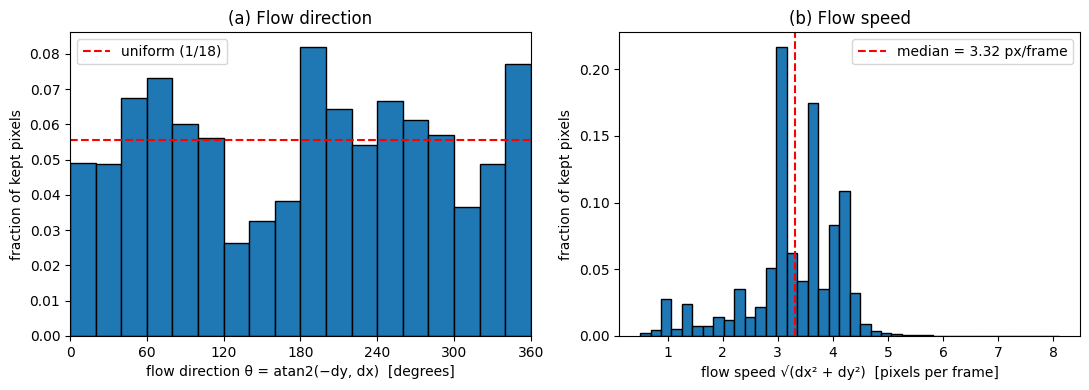

Caption numbers: median speed = 3.32 px/frame, pixels kept = 103,050 (from 950 frame pairs).


In [ ]:
vids = to_float(train_u8[:50]).numpy()

angles, speeds, n_pairs = [], [], 0
for vid in vids:
    for s in range(19):
        a, b = vid[s, 0], vid[s + 1, 0]
        prev = np.round(a * 255).astype(np.uint8)
        nxt  = np.round(b * 255).astype(np.uint8)
        flow = cv2.calcOpticalFlowFarneback(prev, nxt, None, 0.5, 3, 15, 3, 5, 1.2, 0)
        dx, dy = flow[..., 0], flow[..., 1]
        mag = np.sqrt(dx ** 2 + dy ** 2)
        keep = (a > 0.2) & (b > 0.2) & (mag > 0.5)
        angles.append(np.degrees(np.arctan2(-dy[keep], dx[keep])) % 360.0)
        speeds.append(mag[keep])
        n_pairs += 1
assert n_pairs == 950

theta = np.concatenate(angles)
speed = np.concatenate(speeds)
n_kept = theta.size
median_speed = float(np.median(speed))
w = np.full(n_kept, 1.0 / n_kept)

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(11, 4))
ax_a.hist(theta, bins=np.arange(0, 361, 20), weights=w, edgecolor="black")
ax_a.axhline(1 / 18, color="red", linestyle="--", label="uniform (1/18)")
ax_a.set_xlim(0, 360); ax_a.set_xticks(np.arange(0, 361, 60))
ax_a.set_xlabel("flow direction θ = atan2(−dy, dx)  [degrees]")
ax_a.set_ylabel("fraction of kept pixels"); ax_a.set_title("(a) Flow direction"); ax_a.legend()

ax_b.hist(speed, bins=40, weights=w, edgecolor="black")
ax_b.axvline(median_speed, color="red", linestyle="--", label=f"median = {median_speed:.3g} px/frame")
ax_b.set_xlabel("flow speed √(dx² + dy²)  [pixels per frame]")
ax_b.set_ylabel("fraction of kept pixels"); ax_b.set_title("(b) Flow speed"); ax_b.legend()
fig.tight_layout()
fig.savefig(f"{OUT}/figure1_flow.png", dpi=200)
plt.show()

stats = {"n_frame_pairs": n_pairs, "n_pixels_kept": int(n_kept),
         "median_speed_px_per_frame": median_speed,
         "direction_fraction_per_20deg_bin":
             (np.histogram(theta, bins=np.arange(0, 361, 20))[0] / n_kept).round(4).tolist()}
with open(f"{OUT}/figure1_stats.json", "w") as fh:
    json.dump(stats, fh, indent=2)
print(f"Caption numbers: median speed = {median_speed:.3g} px/frame, "
      f"pixels kept = {n_kept:,} (from {n_pairs} frame pairs).")

## Model A

In [ ]:
PATCH, HIDDEN, KERNEL = 4, 64, 3

class ConvLSTMCell(nn.Module):
    def __init__(self, in_channels, hidden_channels):
        super().__init__()
        self.hidden_channels = hidden_channels
        self.conv = nn.Conv2d(in_channels + hidden_channels, 4 * hidden_channels,
                              kernel_size=KERNEL, stride=1, padding=1, bias=True)

    def forward(self, u, h, c):
        i, f, o, g = torch.split(self.conv(torch.cat([u, h], dim=1)), self.hidden_channels, dim=1)
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c

class ModelA(nn.Module):
    def __init__(self):
        super().__init__()
        folded = PATCH * PATCH
        self.cell1 = ConvLSTMCell(folded, HIDDEN)
        self.cell2 = ConvLSTMCell(HIDDEN, HIDDEN)
        self.out = nn.Conv2d(HIDDEN, folded, kernel_size=1, bias=True)

    def step(self, frame, state):
        (h1, c1), (h2, c2) = state
        u = F.pixel_unshuffle(frame, PATCH)
        h1, c1 = self.cell1(u, h1, c1)
        h2, c2 = self.cell2(h1, h2, c2)
        x_next = torch.sigmoid(F.pixel_shuffle(self.out(h2), PATCH))
        return x_next, ((h1, c1), (h2, c2))

    def forward(self, X):
        B, T, C, H, W = X.shape
        assert (T, C, H, W) == (5, 1, 64, 64), X.shape
        zeros = lambda: X.new_zeros(B, HIDDEN, H // PATCH, W // PATCH)
        state = ((zeros(), zeros()), (zeros(), zeros()))
        outputs, x_hat = [], None
        for tau in range(1, 10):
            u = X[:, tau - 1] if tau <= 5 else x_hat
            x_hat, state = self.step(u, state)
            if tau >= 5:
                outputs.append(x_hat)
        return torch.stack(outputs, dim=1)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

model_a = ModelA()
n_params = count_parameters(model_a)
print(f"Model A trainable parameters: {n_params:,}")
assert n_params == 480_784, "handout check: model A has exactly 480,784 trainable parameters"

X_chk, Y_chk, m_chk = make_window(to_float(test_u8[:2]), t=1, k=1)
with torch.no_grad():
    Y_hat_chk = model_a(X_chk)
print("X:", tuple(X_chk.shape), "-> Y_hat:", tuple(Y_hat_chk.shape), "| target mask:", m_chk.tolist())

Model A trainable parameters: 480,784
X: (2, 5, 1, 64, 64) -> Y_hat: (2, 5, 1, 64, 64) | target mask: [True, True, True, True, True]


### Training and evaluation

In [ ]:
BATCH_SIZE, EPOCHS, LR = 32, 30, 1e-3
SEEDS = [0, 1]
RETRAIN = False

def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()

def masked_video_loss(Y_hat, Y, mask):
    mse_h = ((Y_hat - Y) ** 2).mean(dim=(2, 3, 4))
    m = mask.to(mse_h.dtype)
    return ((mse_h * m).sum(dim=1) / m.sum(dim=1)).mean()

def randint(n, gen):
    return int(torch.randint(n, (1,), generator=gen))

def sample_training_batch(videos_u8, regime, symmetry_aug, gen):
    Xs, Ys, Ms = [], [], []
    for v in videos_u8:
        k = 1 if regime == "normal" else (1, 2, 3)[randint(3, gen)]
        starts = allowed_starts(k, regime)
        t = starts[randint(len(starts), gen)]
        X, Y, mask = make_window(to_float(v), t, k)
        if symmetry_aug:
            g = G[randint(len(G), gen)]
            X, Y = apply_g(g, X), apply_g(g, Y)
        Xs.append(X); Ys.append(Y); Ms.append(mask)
    return torch.stack(Xs), torch.stack(Ys), torch.stack(Ms).to(videos_u8.device)

@torch.no_grad()
def per_horizon_mse(predict, videos_u8, t=1, k=1, batch_size=32):
    rows = []
    for b in range(0, len(videos_u8), batch_size):
        v = to_float(videos_u8[b:b + batch_size]).to(device)
        X, Y, mask = make_window(v, t, k)
        rows.append(((predict(X) - Y) ** 2).mean(dim=(2, 3, 4)).double().cpu())
    return torch.cat(rows), mask

def E_H(mse, mask, H):
    assert bool(mask[:H].all()), f"forecast horizons 1..{H} do not all exist"
    return mse[:, :H].mean(dim=1).mean().item()

def train_model(make_model, name, seed, regime="normal", symmetry_aug=False):
    ckpt = f"{OUT}/{name}_seed{seed}.pt"
    if os.path.exists(ckpt) and not RETRAIN:
        saved = torch.load(ckpt, map_location=device)
        model = make_model().to(device)
        model.load_state_dict(saved["state_dict"])
        model.eval()
        print(f"{name} seed {seed}: loaded {ckpt}")
        return model, saved["history"]

    torch.manual_seed(seed)
    model = make_model().to(device)
    gen = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    history = {"epoch_time_s": [], "train_loss": [], "val_E5": [], "hardware": HARDWARE}
    n = len(train_dev)

    for epoch in range(1, EPOCHS + 1):
        model.train()
        sync(); t0 = time.perf_counter()
        perm = torch.randperm(n, generator=gen)
        total = torch.zeros((), device=device)
        for b in range(0, n, BATCH_SIZE):
            idx = perm[b:b + BATCH_SIZE].to(device)
            X, Y, mask = sample_training_batch(train_dev[idx], regime, symmetry_aug, gen)
            loss = masked_video_loss(model(X), Y, mask)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            total += loss.detach() * len(idx)
        sync(); history["epoch_time_s"].append(time.perf_counter() - t0)

        model.eval()
        mse_val, m_val = per_horizon_mse(model, val_u8)
        history["train_loss"].append(total.item() / n)
        history["val_E5"].append(E_H(mse_val, m_val, 5))
        print(f"{name} seed {seed} | epoch {epoch:2d}/{EPOCHS} | train loss {history['train_loss'][-1]:.3e}"
              f" | val E5 {history['val_E5'][-1]:.3e} | {history['epoch_time_s'][-1]:.1f} s")

    torch.save({"state_dict": model.state_dict(), "history": history}, ckpt)
    model.eval()
    return model, history

@torch.no_grad()
def inference_time(predict, videos_u8, batch_size=32):
    predict(make_window(to_float(videos_u8[:batch_size]).to(device), 1, 1)[0]); sync()
    total = 0.0
    for b in range(0, len(videos_u8), batch_size):
        X = make_window(to_float(videos_u8[b:b + batch_size]).to(device), 1, 1)[0]
        sync(); t0 = time.perf_counter()
        predict(X)
        sync(); total += time.perf_counter() - t0
    return total

def fmt(x):
    if x == 0:
        return "0"
    if abs(x) < 1e-3:
        return f"{x:.2e}"
    r = float(f"{x:.2e}")
    e = int(np.floor(np.log10(abs(r))))
    return f"{r:.{max(0, 2 - e)}f}" if e < 3 else f"{r:.3g}"

def fmt_seeds(v0, v1):
    return f"{fmt((v0 + v1) / 2)} ({fmt(v0)}, {fmt(v1)})"

train_dev = train_u8.to(device)
print("Training videos on", train_dev.device, tuple(train_dev.shape))

Training videos on cuda:0 (8000, 20, 1, 64, 64)


### Training model A

model_A seed 0 | epoch  1/30 | train loss 4.611e-02 | val E5 3.931e-02 | 13.8 s
model_A seed 0 | epoch  2/30 | train loss 3.967e-02 | val E5 3.864e-02 | 11.6 s
model_A seed 0 | epoch  3/30 | train loss 3.866e-02 | val E5 3.762e-02 | 11.7 s
model_A seed 0 | epoch  4/30 | train loss 3.718e-02 | val E5 3.596e-02 | 11.7 s
model_A seed 0 | epoch  5/30 | train loss 3.527e-02 | val E5 3.424e-02 | 11.8 s
model_A seed 0 | epoch  6/30 | train loss 3.370e-02 | val E5 3.226e-02 | 11.9 s
model_A seed 0 | epoch  7/30 | train loss 3.231e-02 | val E5 3.116e-02 | 12.1 s
model_A seed 0 | epoch  8/30 | train loss 3.125e-02 | val E5 3.035e-02 | 12.1 s
model_A seed 0 | epoch  9/30 | train loss 3.043e-02 | val E5 2.968e-02 | 11.9 s
model_A seed 0 | epoch 10/30 | train loss 2.971e-02 | val E5 2.914e-02 | 11.9 s
model_A seed 0 | epoch 11/30 | train loss 2.927e-02 | val E5 2.907e-02 | 11.9 s
model_A seed 0 | epoch 12/30 | train loss 2.872e-02 | val E5 2.824e-02 | 11.9 s
model_A seed 0 | epoch 13/30 | train los

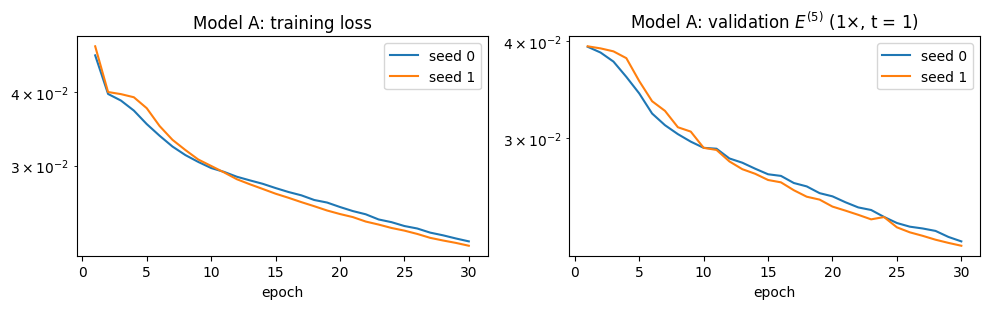

In [ ]:
models_A, hist_A = {}, {}
for s in SEEDS:
    models_A[s], hist_A[s] = train_model(ModelA, "model_A", s, regime="normal", symmetry_aug=False)

timing_A = {s: {"train_s_per_epoch": float(np.mean(hist_A[s]["epoch_time_s"])),
                "inference_s": inference_time(models_A[s], test_u8)} for s in SEEDS}
with open(f"{OUT}/timing_model_A.json", "w") as fh:
    json.dump({"hardware": HARDWARE, **{f"seed{s}": timing_A[s] for s in SEEDS}}, fh, indent=2)

print(f"Hardware: {HARDWARE}")
print("Training time per epoch [s]:", fmt_seeds(timing_A[0]["train_s_per_epoch"], timing_A[1]["train_s_per_epoch"]))
print("Inference time, 1,000 test videos [s]:", fmt_seeds(timing_A[0]["inference_s"], timing_A[1]["inference_s"]))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for s in SEEDS:
    ax[0].plot(range(1, len(hist_A[s]["train_loss"]) + 1), hist_A[s]["train_loss"], label=f"seed {s}")
    ax[1].plot(range(1, len(hist_A[s]["val_E5"]) + 1), hist_A[s]["val_E5"], label=f"seed {s}")
ax[0].set_title("Model A: training loss"); ax[1].set_title("Model A: validation $E^{(5)}$ (1×, t = 1)")
for a in ax:
    a.set_xlabel("epoch"); a.set_yscale("log"); a.legend()
fig.tight_layout(); plt.show()

### Table 2

In [ ]:
def blank(X):
    return torch.zeros_like(X)

def copy_last(X):
    return X[:, -1:].expand_as(X).contiguous()

mse_A = {}
for s in SEEDS:
    mse_A[s], mask_1x = per_horizon_mse(models_A[s], test_u8, t=1, k=1)
mse_blank, _ = per_horizon_mse(blank, test_u8, t=1, k=1)
mse_copy, _ = per_horizon_mse(copy_last, test_u8, t=1, k=1)
np.savez(f"{OUT}/per_video_mse_1x.npz", model_A_seed0=mse_A[0].numpy(), model_A_seed1=mse_A[1].numpy(),
         blank=mse_blank.numpy(), copy_last=mse_copy.numpy())

header = "| Predictor | MSE₁ | MSE₂ | MSE₃ | MSE₄ | MSE₅ | E⁽⁵⁾ | Trainable parameters |"
lines = ["**Table 2: test-set errors at 1× (t = 1). Model A entries are mean (seed 0, seed 1).**", "",
         header, "|---|---|---|---|---|---|---|---|"]
hA = [[mse_A[s][:, h].mean().item() for h in range(5)] for s in SEEDS]
eA = [E_H(mse_A[s], mask_1x, 5) for s in SEEDS]
lines.append("| Model A | " + " | ".join(fmt_seeds(hA[0][h], hA[1][h]) for h in range(5))
             + f" | {fmt_seeds(eA[0], eA[1])} | {count_parameters(models_A[0]):,} |")
for name, mse in [("Blank", mse_blank), ("Copy-last", mse_copy)]:
    lines.append(f"| {name} | " + " | ".join(fmt(mse[:, h].mean().item()) for h in range(5))
                 + f" | {fmt(E_H(mse, mask_1x, 5))} | 0 |")
table2 = "\n".join(lines)
display(Markdown(table2))
with open(f"{OUT}/table2.md", "w") as fh:
    fh.write(table2 + "\n")

**Table 2: test-set errors at 1× (t = 1). Model A entries are mean (seed 0, seed 1).**

| Predictor | MSE₁ | MSE₂ | MSE₃ | MSE₄ | MSE₅ | E⁽⁵⁾ | Trainable parameters |
|---|---|---|---|---|---|---|---|
| Model A | 0.0172 (0.0174, 0.0169) | 0.0205 (0.0207, 0.0203) | 0.0227 (0.0229, 0.0225) | 0.0243 (0.0245, 0.0242) | 0.0260 (0.0261, 0.0258) | 0.0221 (0.0223, 0.0219) | 480,784 |
| Blank | 0.0426 | 0.0426 | 0.0426 | 0.0425 | 0.0425 | 0.0426 | 0 |
| Copy-last | 0.0492 | 0.0604 | 0.0669 | 0.0708 | 0.0732 | 0.0641 | 0 |

### Figure 2

test video 257 (dataset index 9257): overlap score 0.000
test video 763 (dataset index 9763): overlap score 0.000
test video 191 (dataset index 9191): overlap score 0.346


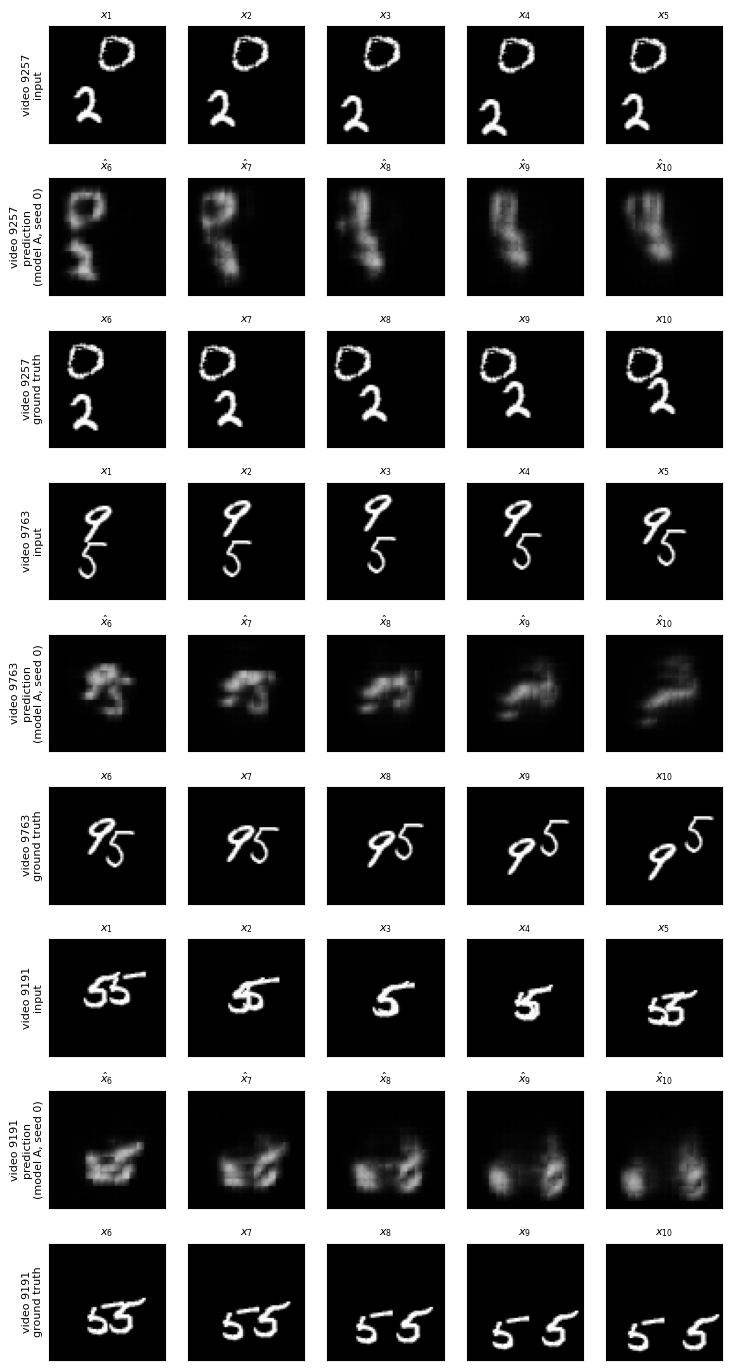

In [ ]:
FIG2_VIDEOS = None

test_f = to_float(test_u8)
ink = (test_f[:, :, 0] > 0.2).flatten(2).sum(-1).float()
overlap = 1 - ink[:, :10].min(dim=1).values / ink.max(dim=1).values.clamp(min=1)
if FIG2_VIDEOS is None:
    order = torch.argsort(overlap).tolist()
    FIG2_VIDEOS = [order[0], order[1], order[-1]]
for vi in FIG2_VIDEOS:
    print(f"test video {vi} (dataset index {9000 + vi}): overlap score {overlap[vi]:.3f}")

model0 = models_A[0]
fig, axes = plt.subplots(3 * len(FIG2_VIDEOS), 5, figsize=(7.5, 4.6 * len(FIG2_VIDEOS)))
for r, vi in enumerate(FIG2_VIDEOS):
    X, Y, _ = make_window(to_float(test_u8[vi:vi + 1]).to(device), t=1, k=1)
    with torch.no_grad():
        Y_hat = model0(X)
    rows = [("input", X, [f"$x_{{{f}}}$" for f in range(1, 6)]),
            ("prediction\n(model A, seed 0)", Y_hat, [f"$\\hat{{x}}_{{{f}}}$" for f in range(6, 11)]),
            ("ground truth", Y, [f"$x_{{{f}}}$" for f in range(6, 11)])]
    for rr, (label, seq, titles) in enumerate(rows):
        for c in range(5):
            ax = axes[3 * r + rr, c]
            ax.imshow(seq[0, c, 0].cpu(), cmap="gray", vmin=0, vmax=1)
            ax.set_xticks([]); ax.set_yticks([])
            ax.set_title(titles[c], fontsize=8)
        axes[3 * r + rr, 0].set_ylabel(f"video {9000 + vi}\n{label}", fontsize=8)
fig.tight_layout()
fig.savefig(f"{OUT}/figure2_modelA.png", dpi=200)
plt.show()

## Testing the baseline
### Table 3

In [ ]:
TRANSFORMS = {"M": mirror, "R": rotate}

@torch.no_grad()
def consistency_metrics(predict, videos_u8, T, batch_size=32):
    C, E = [], []
    for b in range(0, len(videos_u8), batch_size):
        v = to_float(videos_u8[b:b + batch_size]).to(device)
        X, Y, mask = make_window(v, t=1, k=1)
        assert bool(mask.all())
        f_X = predict(X)
        f_TX = predict(T(X))
        C.append(((f_TX - T(f_X)) ** 2).mean(dim=(1, 2, 3, 4)).double().cpu())
        E.append(((f_TX - T(Y)) ** 2).mean(dim=(1, 2, 3, 4)).double().cpu())
    return torch.cat(C), torch.cat(E)

cons = {f"A_seed{s}": {n: consistency_metrics(models_A[s], test_u8, T) for n, T in TRANSFORMS.items()} for s in SEEDS}
cons["Blank"] = {n: consistency_metrics(blank, test_u8, T) for n, T in TRANSFORMS.items()}
cons["Copy-last"] = {n: consistency_metrics(copy_last, test_u8, T) for n, T in TRANSFORMS.items()}
np.savez(f"{OUT}/per_video_consistency_1x.npz",
         **{f"{p}_{q}_{n}": cons[p][n][i].numpy() for p in cons for n in TRANSFORMS for i, q in enumerate("CE")})

def avg(x):
    return x.mean().item()

lines = ["**Table 3: consistency gaps and transformed errors at 1× (t = 1). Model A entries are mean (seed 0, seed 1).**", "",
         "| Predictor | E⁽⁵⁾ | C_M | E_M | C_R | E_R |", "|---|---|---|---|---|---|"]
row = [fmt_seeds(eA[0], eA[1])]
for n in TRANSFORMS:
    for i in range(2):
        row.append(fmt_seeds(avg(cons["A_seed0"][n][i]), avg(cons["A_seed1"][n][i])))
lines.append("| Model A | " + " | ".join(row) + " |")
for name, mse in [("Blank", mse_blank), ("Copy-last", mse_copy)]:
    row = [fmt(E_H(mse, mask_1x, 5))] + [fmt(avg(cons[name][n][i])) for n in TRANSFORMS for i in range(2)]
    lines.append(f"| {name} | " + " | ".join(row) + " |")
table3 = "\n".join(lines)
display(Markdown(table3))
with open(f"{OUT}/table3.md", "w") as fh:
    fh.write(table3 + "\n")

**Table 3: consistency gaps and transformed errors at 1× (t = 1). Model A entries are mean (seed 0, seed 1).**

| Predictor | E⁽⁵⁾ | C_M | E_M | C_R | E_R |
|---|---|---|---|---|---|
| Model A | 0.0221 (0.0223, 0.0219) | 0.00180 (0.00169, 0.00191) | 0.0227 (0.0229, 0.0226) | 0.00296 (0.00280, 0.00312) | 0.0238 (0.0239, 0.0237) |
| Blank | 0.0426 | 0 | 0.0426 | 0 | 0.0426 |
| Copy-last | 0.0641 | 0 | 0.0641 | 0 | 0.0641 |

### Figures 3 and 4

T = M: test video 256 (dataset index 9256), per-video C_M = 0.00469
T = M: test video 269 (dataset index 9269), per-video C_M = 0.00448
T = R: test video 733 (dataset index 9733), per-video C_R = 0.00662
T = R: test video 254 (dataset index 9254), per-video C_R = 0.00647


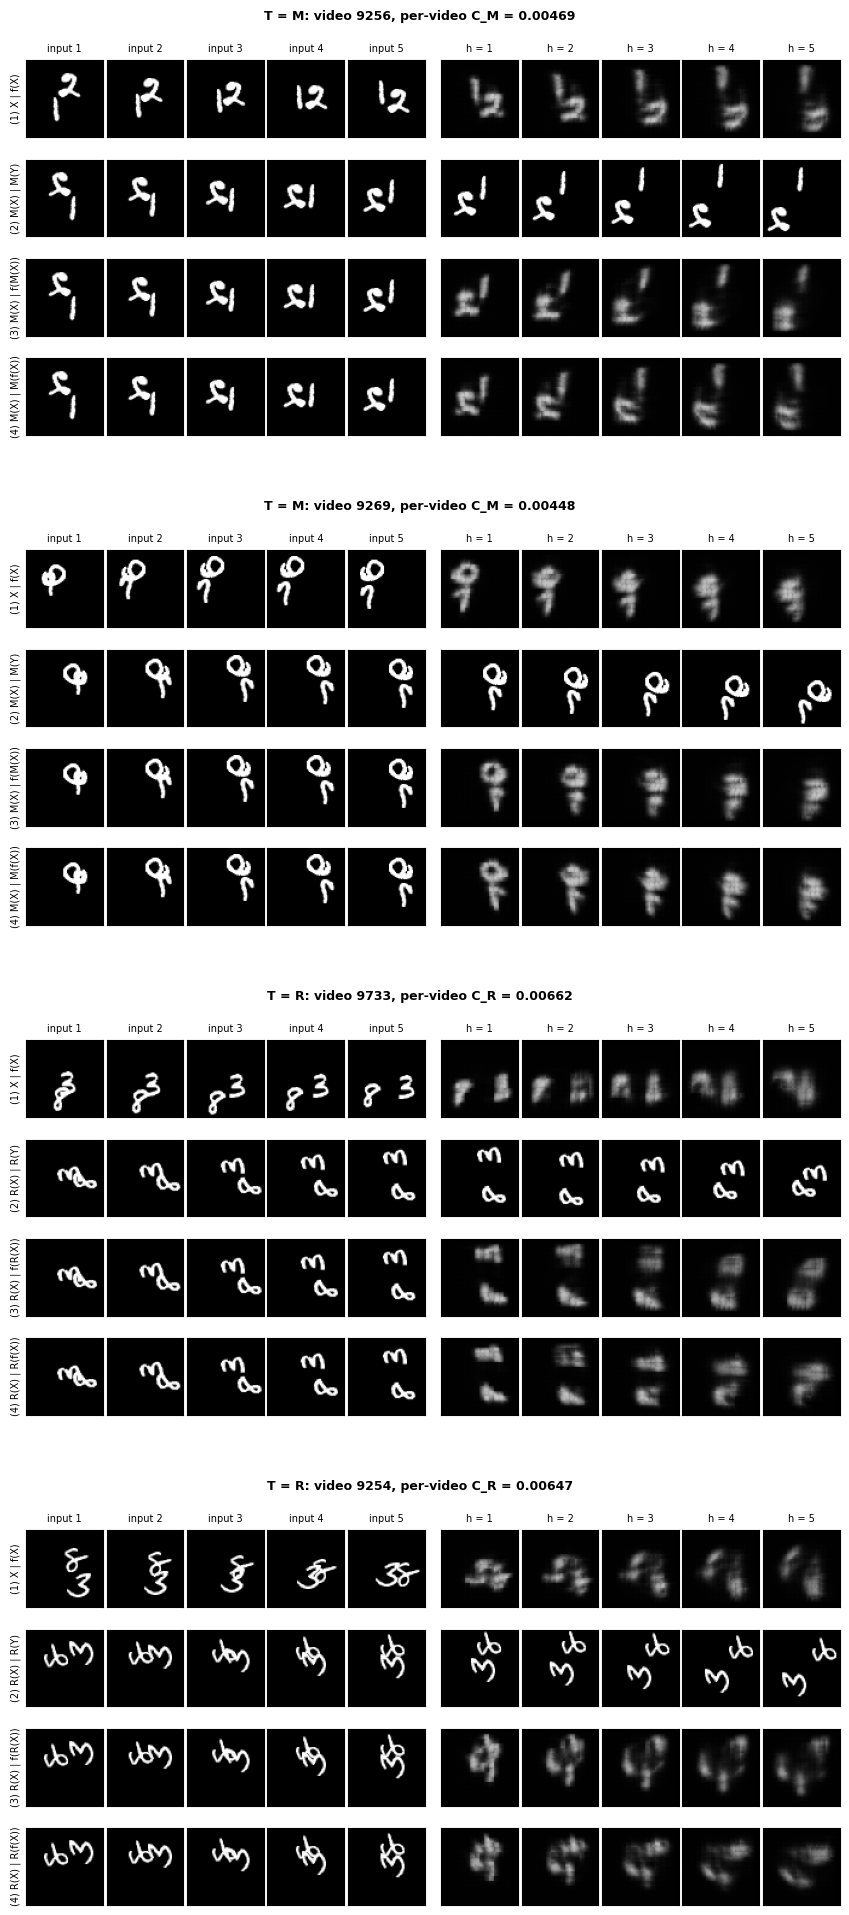

GIFs (copy into your repository and cite in the Figure 3 caption):
   gifs/figure3_M_video9256.gif
   gifs/figure3_M_video9269.gif
   gifs/figure3_R_video9733.gif
   gifs/figure3_R_video9254.gif


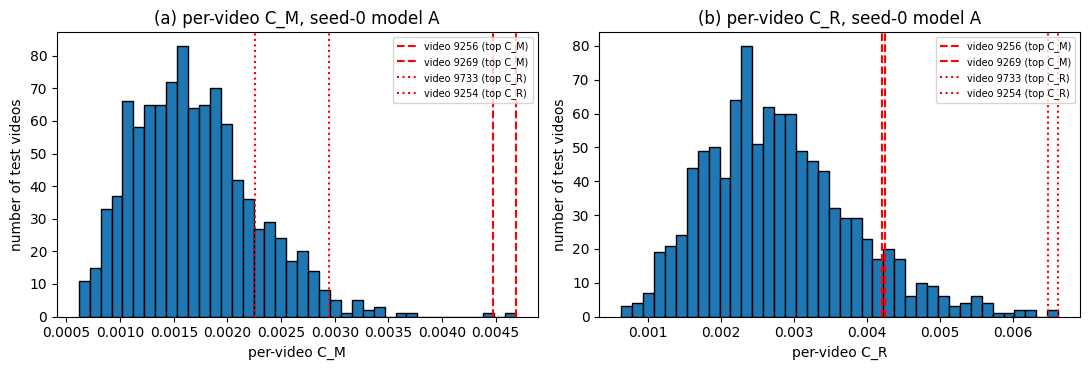

In [ ]:
from PIL import Image

model0 = models_A[0]
C_seed0 = {n: cons["A_seed0"][n][0] for n in TRANSFORMS}
fig3_panels = [(n, int(i)) for n in TRANSFORMS for i in torch.argsort(C_seed0[n], descending=True)[:2]]
for n, vi in fig3_panels:
    print(f"T = {n}: test video {vi} (dataset index {9000 + vi}), per-video C_{n} = {fmt(C_seed0[n][vi].item())}")

@torch.no_grad()
def panel_rows(vi, T):
    X, Y, _ = make_window(to_float(test_u8[vi:vi + 1]).to(device), t=1, k=1)
    f_X, f_TX = model0(X), model0(T(X))
    n = [k for k, v in TRANSFORMS.items() if v is T][0]
    rows = [("(1) X | f(X)", X, f_X),
            (f"(2) {n}(X) | {n}(Y)", T(X), T(Y)),
            (f"(3) {n}(X) | f({n}(X))", T(X), f_TX),
            (f"(4) {n}(X) | {n}(f(X))", T(X), T(f_X))]
    return [(lab, a[0, :, 0].cpu().numpy(), b[0, :, 0].cpu().numpy()) for lab, a, b in rows]

n_pan = len(fig3_panels)
fig = plt.figure(figsize=(10.5, 4.9 * n_pan))
subfigs = fig.subfigures(n_pan, 1)
for sf, (n, vi) in zip(np.atleast_1d(subfigs), fig3_panels):
    rows = panel_rows(vi, TRANSFORMS[n])
    gs = sf.add_gridspec(4, 11, width_ratios=[1] * 5 + [0.12] + [1] * 5, hspace=0.25, wspace=0.05)
    for r, (lab, inp, fut) in enumerate(rows):
        for c in range(10):
            ax = sf.add_subplot(gs[r, c if c < 5 else c + 1])
            ax.imshow(inp[c] if c < 5 else fut[c - 5], cmap="gray", vmin=0, vmax=1)
            ax.set_xticks([]); ax.set_yticks([])
            if r == 0:
                ax.set_title(f"input {c + 1}" if c < 5 else f"h = {c - 4}", fontsize=7)
            if c == 0:
                ax.set_ylabel(lab, fontsize=7)
    sf.suptitle(f"T = {n}: video {9000 + vi}, per-video C_{n} = {fmt(C_seed0[n][vi].item())}",
                fontsize=9, weight="bold")
fig.savefig(f"{OUT}/figure3_modelA.png", dpi=200, bbox_inches="tight")
plt.show()

GIF_DIR = f"{OUT}/gifs"
os.makedirs(GIF_DIR, exist_ok=True)
gif_paths = []
for n, vi in fig3_panels:
    rows = panel_rows(vi, TRANSFORMS[n])
    frames = []
    for h in range(5):
        f, ax = plt.subplots(4, 2, figsize=(3.6, 6.6))
        for r, (lab, inp, fut) in enumerate(rows):
            ax[r, 0].imshow(inp[-1], cmap="gray", vmin=0, vmax=1)
            ax[r, 1].imshow(fut[h], cmap="gray", vmin=0, vmax=1)
            ax[r, 0].set_ylabel(lab, fontsize=7)
            for a in ax[r]:
                a.set_xticks([]); a.set_yticks([])
        ax[0, 0].set_title("input 5", fontsize=8)
        ax[0, 1].set_title(f"h = {h + 1}", fontsize=8)
        f.suptitle(f"T = {n}, video {9000 + vi}", fontsize=9)
        f.tight_layout()
        f.canvas.draw()
        frames.append(Image.fromarray(np.asarray(f.canvas.buffer_rgba())[..., :3].copy()))
        plt.close(f)
    path = f"{GIF_DIR}/figure3_{n}_video{9000 + vi}.gif"
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=700, loop=0)
    gif_paths.append(path)
print("GIFs (copy into your repository and cite in the Figure 3 caption):")
for p in gif_paths:
    print("  ", p.replace(OUT + "/", ""))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
styles = {"M": "--", "R": ":"}
for ax, n in zip(axes, TRANSFORMS):
    vals = C_seed0[n].numpy()
    ax.hist(vals, bins=40, edgecolor="black")
    for m, vi in fig3_panels:
        ax.axvline(vals[vi], color="red", linestyle=styles[m], label=f"video {9000 + vi} (top C_{m})")
    ax.set_xlabel(f"per-video C_{n}")
    ax.set_ylabel("number of test videos")
    ax.set_title(f"({'a' if n == 'M' else 'b'}) per-video C_{n}, seed-0 model A")
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(f"{OUT}/figure4_modelA.png", dpi=200)
plt.show()

### Table 4

In [ ]:
SPEEDS = [1, 2, 3]
speed_mse = {(f"A_seed{s}", k): per_horizon_mse(models_A[s], test_u8, t=1, k=k) for s in SEEDS for k in SPEEDS}
speed_mse.update({("Copy-last", k): per_horizon_mse(copy_last, test_u8, t=1, k=k) for k in SPEEDS})
for k in SPEEDS:
    print(f"{k}x: target horizons that exist = {speed_mse[('Copy-last', k)][1].tolist()}")
np.savez(f"{OUT}/per_video_mse_speeds.npz", **{f"{p}_{k}x": m.numpy() for (p, k), (m, _) in speed_mse.items()})

def E_speed(pred, k, H):
    m, mask = speed_mse[(pred, k)]
    return E_H(m, mask, H)

cols = [("E⁽²⁾ 1×", 1, 2), ("E⁽²⁾ 2×", 2, 2), ("E⁽²⁾ 3×", 3, 2), ("E⁽⁵⁾ 1×", 1, 5), ("E⁽⁵⁾ 2×", 2, 5)]
lines = ["**Table 4: model A at faster speeds (t = 1). Model A entries are mean (seed 0, seed 1).**", "",
         "| Predictor | " + " | ".join(c[0] for c in cols) + " |", "|---|" + "---|" * len(cols)]
lines.append("| Model A | " + " | ".join(fmt_seeds(E_speed("A_seed0", k, H), E_speed("A_seed1", k, H))
                                         for _, k, H in cols) + " |")
lines.append("| Copy-last | " + " | ".join(fmt(E_speed("Copy-last", k, H)) for _, k, H in cols) + " |")
table4 = "\n".join(lines)
display(Markdown(table4))
with open(f"{OUT}/table4.md", "w") as fh:
    fh.write(table4 + "\n")

1x: target horizons that exist = [True, True, True, True, True]
2x: target horizons that exist = [True, True, True, True, True]
3x: target horizons that exist = [True, True, False, False, False]


**Table 4: model A at faster speeds (t = 1). Model A entries are mean (seed 0, seed 1).**

| Predictor | E⁽²⁾ 1× | E⁽²⁾ 2× | E⁽²⁾ 3× | E⁽⁵⁾ 1× | E⁽⁵⁾ 2× |
|---|---|---|---|---|---|
| Model A | 0.0188 (0.0191, 0.0186) | 0.0449 (0.0440, 0.0459) | 0.0525 (0.0520, 0.0531) | 0.0221 (0.0223, 0.0219) | 0.0502 (0.0491, 0.0514) |
| Copy-last | 0.0548 | 0.0661 | 0.0703 | 0.0641 | 0.0719 |

### Figure 5

Figure 5 video: test video 26 (dataset index 9026); 56 test videos have no overlap in any frame


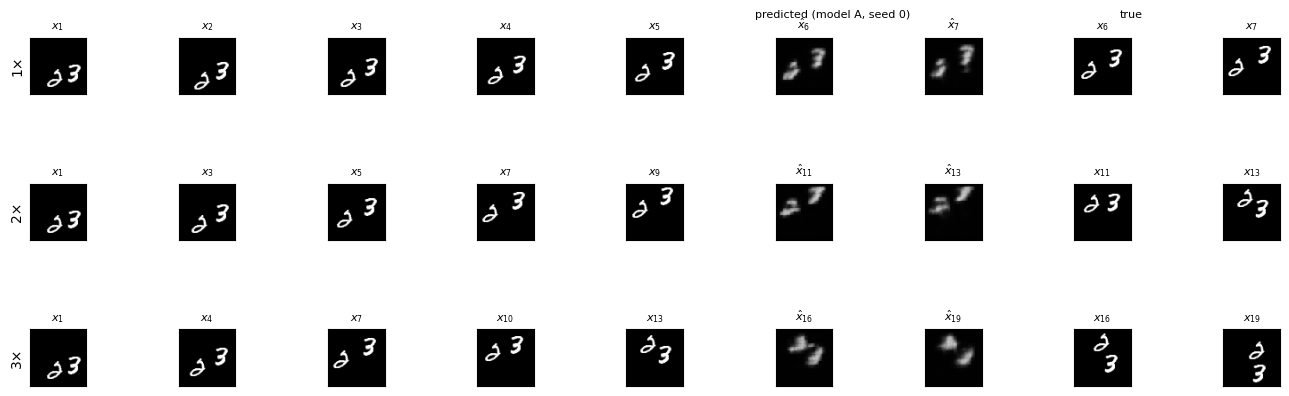

In [ ]:
FIG5_VIDEO = None

test_f = to_float(test_u8)
ink_all = (test_f[:, :, 0] > 0.2).flatten(2).sum(-1)
no_overlap = (ink_all == ink_all[:, :1]).all(dim=1)
if FIG5_VIDEO is None:
    FIG5_VIDEO = int(torch.nonzero(no_overlap)[0])
print(f"Figure 5 video: test video {FIG5_VIDEO} (dataset index {9000 + FIG5_VIDEO}); "
      f"{int(no_overlap.sum())} test videos have no overlap in any frame")

fig, axes = plt.subplots(3, 9, figsize=(13, 4.8))
for r, k in enumerate(SPEEDS):
    X, Y, mask = make_window(to_float(test_u8[FIG5_VIDEO:FIG5_VIDEO + 1]).to(device), t=1, k=k)
    with torch.no_grad():
        Y_hat = model0(X)
    ins, tgs = window_frames(1, k)
    panels = ([(X[0, j, 0], f"$x_{{{ins[j]}}}$") for j in range(5)]
              + [(Y_hat[0, j, 0], f"$\\hat{{x}}_{{{tgs[j]}}}$") for j in range(2)]
              + [(Y[0, j, 0], f"$x_{{{tgs[j]}}}$") for j in range(2)])
    for c, (img, title) in enumerate(panels):
        ax = axes[r, c]
        ax.imshow(img.cpu(), cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(title, fontsize=8)
    axes[r, 0].set_ylabel(f"{k}×", fontsize=10)
axes[0, 5].annotate("predicted (model A, seed 0)", (1.0, 1.35), xycoords="axes fraction", ha="center", fontsize=8)
axes[0, 7].annotate("true", (1.0, 1.35), xycoords="axes fraction", ha="center", fontsize=8)
fig.tight_layout()
fig.savefig(f"{OUT}/figure5_modelA.png", dpi=200)
plt.show()

## What can data fix?

In [ ]:
class ConvLSTMCellDilated(nn.Module):
    def __init__(self, in_channels, hidden_channels, dilation):
        super().__init__()
        self.hidden_channels = hidden_channels
        self.conv = nn.Conv2d(in_channels + hidden_channels, 4 * hidden_channels, kernel_size=KERNEL,
                              stride=1, padding=dilation, dilation=dilation, bias=True)

    def forward(self, u, h, c):
        i, f, o, g = torch.split(self.conv(torch.cat([u, h], dim=1)), self.hidden_channels, dim=1)
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c

class ModelD(ModelA):
    def __init__(self):
        super().__init__()
        self.cell2 = ConvLSTMCellDilated(HIDDEN, HIDDEN, dilation=2)

PARAM_LIMIT = 721_176
n_D = count_parameters(ModelD())
print(f"Model D trainable parameters: {n_D:,} (limit {PARAM_LIMIT:,})")
assert n_D <= PARAM_LIMIT
X_chk = make_window(to_float(test_u8[:2]).to(device), t=1, k=1)[0]
with torch.no_grad():
    assert ModelD().to(device)(X_chk).shape == X_chk.shape
print("Model D input/output shapes match model A:", tuple(X_chk.shape))

Model D trainable parameters: 480,784 (limit 721,176)
Model D input/output shapes match model A: (2, 5, 1, 64, 64)


### Reach check

In [ ]:
def one_step_reach(model, p0=8, q0=8):
    model = model.to(device).eval()
    g = HIDDEN
    u = torch.rand(1, 1, 64, 64, device=device, requires_grad=True)
    st = [torch.randn(1, g, 16, 16, device=device, requires_grad=True) for _ in range(4)]
    x_next, _ = model.step(u, ((st[0], st[1]), (st[2], st[3])))
    x_next[0, 0, 4 * p0:4 * p0 + 4, 4 * q0:4 * q0 + 4].sum().backward()
    grads = {"u (new input)": u.grad[0, 0].reshape(16, 4, 16, 4).abs().sum(dim=(1, 3)),
             "h1 (previous)": st[0].grad[0].abs().sum(0), "c1 (previous)": st[1].grad[0].abs().sum(0),
             "h2 (previous)": st[2].grad[0].abs().sum(0), "c2 (previous)": st[3].grad[0].abs().sum(0)}
    out = {}
    for name, gmap in grads.items():
        cells = torch.nonzero(gmap > 0)
        dp, dq = (cells[:, 0] - p0).abs(), (cells[:, 1] - q0).abs()
        reach_cells = int(torch.maximum(dp, dq).max())
        diag_px = float(4 * torch.sqrt((dp ** 2 + dq ** 2).float()).max())
        full = len(cells) == (2 * reach_cells + 1) ** 2
        out[name] = (reach_cells, 4 * reach_cells, diag_px, full)
    return out

lines = ["**One-step reach from the gradient check (output patch at grid cell (8, 8)).**", "",
         "| Model | Source | Reach (cells) | Reach along axis (px) | Furthest diagonal (px) | No gaps |",
         "|---|---|---|---|---|---|"]
for name, m in [("A", models_A[0]), ("D", ModelD())]:
    for src, (rc, rpx, dpx, full) in one_step_reach(m).items():
        lines.append(f"| {name} | {src} | {rc} | {rpx} | {dpx:.1f} | {'yes' if full else 'no'} |")
display(Markdown("\n".join(lines)))

**One-step reach from the gradient check (output patch at grid cell (8, 8)).**

| Model | Source | Reach (cells) | Reach along axis (px) | Furthest diagonal (px) | No gaps |
|---|---|---|---|---|---|
| A | u (new input) | 2 | 8 | 11.3 | yes |
| A | h1 (previous) | 2 | 8 | 11.3 | yes |
| A | c1 (previous) | 1 | 4 | 5.7 | yes |
| A | h2 (previous) | 1 | 4 | 5.7 | yes |
| A | c2 (previous) | 0 | 0 | 0.0 | yes |
| D | u (new input) | 3 | 12 | 17.0 | yes |
| D | h1 (previous) | 3 | 12 | 17.0 | yes |
| D | c1 (previous) | 2 | 8 | 11.3 | no |
| D | h2 (previous) | 2 | 8 | 11.3 | no |
| D | c2 (previous) | 0 | 0 | 0.0 | yes |

### Training models B, C and D

model_B seed 0 | epoch  1/30 | train loss 4.611e-02 | val E5 3.932e-02 | 12.4 s
model_B seed 0 | epoch  2/30 | train loss 3.966e-02 | val E5 3.857e-02 | 12.5 s
model_B seed 0 | epoch  3/30 | train loss 3.867e-02 | val E5 3.747e-02 | 12.5 s
model_B seed 0 | epoch  4/30 | train loss 3.714e-02 | val E5 3.568e-02 | 12.4 s
model_B seed 0 | epoch  5/30 | train loss 3.530e-02 | val E5 3.393e-02 | 12.3 s
model_B seed 0 | epoch  6/30 | train loss 3.368e-02 | val E5 3.234e-02 | 12.3 s
model_B seed 0 | epoch  7/30 | train loss 3.250e-02 | val E5 3.126e-02 | 12.3 s
model_B seed 0 | epoch  8/30 | train loss 3.135e-02 | val E5 3.042e-02 | 12.3 s
model_B seed 0 | epoch  9/30 | train loss 3.043e-02 | val E5 2.997e-02 | 12.4 s
model_B seed 0 | epoch 10/30 | train loss 2.993e-02 | val E5 2.977e-02 | 12.5 s
model_B seed 0 | epoch 11/30 | train loss 2.927e-02 | val E5 2.881e-02 | 12.4 s
model_B seed 0 | epoch 12/30 | train loss 2.898e-02 | val E5 2.840e-02 | 12.4 s
model_B seed 0 | epoch 13/30 | train los

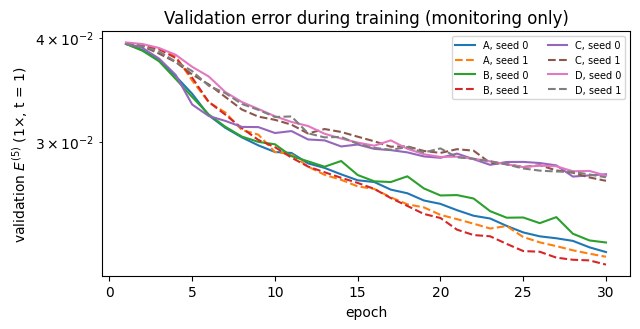

In [ ]:
MODEL_SPECS = {
    "A": (ModelA, "normal", False),
    "B": (ModelA, "normal", True),
    "C": (ModelA, "speed", False),
    "D": (ModelD, "speed", False),
}
models = {("A", s): models_A[s] for s in SEEDS}
hists = {("A", s): hist_A[s] for s in SEEDS}
for name in ["B", "C", "D"]:
    arch, regime, sym = MODEL_SPECS[name]
    for s in SEEDS:
        models[(name, s)], hists[(name, s)] = train_model(arch, f"model_{name}", s, regime=regime, symmetry_aug=sym)

fig, ax = plt.subplots(figsize=(6.5, 3.4))
for name in MODEL_SPECS:
    for s in SEEDS:
        v = hists[(name, s)]["val_E5"]
        ax.plot(range(1, len(v) + 1), v, label=f"{name}, seed {s}", linestyle="-" if s == 0 else "--")
ax.set_xlabel("epoch"); ax.set_ylabel("validation $E^{(5)}$ (1×, t = 1)"); ax.set_yscale("log")
ax.set_title("Validation error during training (monitoring only)")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout(); fig.savefig(f"{OUT}/training_curves_ABCD.png", dpi=200); plt.show()

### Table 5

In [ ]:
results = {}
for (name, s), m in models.items():
    m.eval()
    r = {}
    for k in SPEEDS:
        mse, mask = per_horizon_mse(m, test_u8, t=1, k=k)
        r[f"E2_{k}x"] = E_H(mse, mask, 2)
        if k == 1:
            r["E5_1x"] = E_H(mse, mask, 5)
    for n, T in TRANSFORMS.items():
        C, E = consistency_metrics(m, test_u8, T)
        r[f"C_{n}"], r[f"E_{n}"] = C.mean().item(), E.mean().item()
    r["params"] = count_parameters(m)
    r["train_s"] = float(np.mean(hists[(name, s)]["epoch_time_s"]))
    r["infer_s"] = inference_time(m, test_u8)
    results[(name, s)] = r
with open(f"{OUT}/table5_raw.json", "w") as fh:
    json.dump({"hardware": HARDWARE, **{f"{n}_seed{s}": r for (n, s), r in results.items()}}, fh, indent=2)

cols = [("E⁽⁵⁾ 1×", "E5_1x"), ("C_M", "C_M"), ("E_M", "E_M"), ("C_R", "C_R"), ("E_R", "E_R"),
        ("E⁽²⁾ 1×", "E2_1x"), ("E⁽²⁾ 2×", "E2_2x"), ("E⁽²⁾ 3×", "E2_3x"),
        ("Train time / epoch (s)", "train_s"), ("Inference time (s)", "infer_s")]
lines = [f"**Table 5: models A–D on the test set (t = 1); entries are mean (seed 0, seed 1); hardware: {HARDWARE}.**", "",
         "| Model | " + " | ".join(c[0] for c in cols) + " | Trainable parameters |",
         "|---|" + "---|" * (len(cols) + 1)]
for name in MODEL_SPECS:
    r0, r1 = results[(name, 0)], results[(name, 1)]
    lines.append(f"| {name} | " + " | ".join(fmt_seeds(r0[key], r1[key]) for _, key in cols) + f" | {r0['params']:,} |")
table5 = "\n".join(lines)
display(Markdown(table5))
with open(f"{OUT}/table5.md", "w") as fh:
    fh.write(table5 + "\n")

**Table 5: models A–D on the test set (t = 1); entries are mean (seed 0, seed 1); hardware: Tesla T4.**

| Model | E⁽⁵⁾ 1× | C_M | E_M | C_R | E_R | E⁽²⁾ 1× | E⁽²⁾ 2× | E⁽²⁾ 3× | Train time / epoch (s) | Inference time (s) | Trainable parameters |
|---|---|---|---|---|---|---|---|---|---|---|---|
| A | 0.0221 (0.0223, 0.0219) | 0.00180 (0.00169, 0.00191) | 0.0227 (0.0229, 0.0226) | 0.00296 (0.00280, 0.00312) | 0.0238 (0.0239, 0.0237) | 0.0188 (0.0191, 0.0186) | 0.0449 (0.0440, 0.0459) | 0.0525 (0.0520, 0.0531) | 11.9 (12.0, 11.9) | 0.393 (0.392, 0.394) | 480,784 |
| B | 0.0222 (0.0229, 0.0214) | 0.00139 (0.00117, 0.00161) | 0.0222 (0.0229, 0.0214) | 0.00171 (0.00155, 0.00187) | 0.0222 (0.0228, 0.0215) | 0.0184 (0.0189, 0.0178) | 0.0446 (0.0448, 0.0444) | 0.0516 (0.0522, 0.0511) | 12.4 (12.4, 12.4) | 0.394 (0.394, 0.393) | 480,784 |
| C | 0.0275 (0.0278, 0.0272) | 0.00114 (0.00136, 9.17e-04) | 0.0277 (0.0279, 0.0275) | 0.00229 (0.00233, 0.00225) | 0.0286 (0.0288, 0.0284) | 0.0239 (0.0240, 0.0237) | 0.0292 (0.0293, 0.0291) | 0.0335 (0.0335, 0.0335) | 11.8 (11.8, 11.8) | 0.393 (0.393, 0.394) | 480,784 |
| D | 0.0275 (0.0276, 0.0274) | 8.50e-04 (9.10e-04, 7.89e-04) | 0.0277 (0.0278, 0.0276) | 0.00220 (0.00193, 0.00247) | 0.0286 (0.0285, 0.0287) | 0.0245 (0.0247, 0.0243) | 0.0290 (0.0291, 0.0289) | 0.0326 (0.0326, 0.0327) | 17.3 (17.3, 17.3) | 0.641 (0.641, 0.642) | 480,784 |

### Model comparisons

In [ ]:
def mean2(name, key):
    return (results[(name, 0)][key] + results[(name, 1)][key]) / 2

comparisons = [
    ("B vs A", "symmetry augmentation", ["C_M", "E_M", "C_R", "E_R", "E2_2x", "E2_3x", "E5_1x"]),
    ("C vs A", "speed augmentation", ["E2_2x", "E2_3x", "C_M", "C_R", "E5_1x"]),
    ("D vs C", "larger reach (same data)", ["E2_2x", "E2_3x", "C_M", "C_R", "E5_1x"]),
]
labels = {"C_M": "C_M", "E_M": "E_M", "C_R": "C_R", "E_R": "E_R", "E2_1x": "E⁽²⁾ 1×", "E2_2x": "E⁽²⁾ 2×",
          "E2_3x": "E⁽²⁾ 3×", "E5_1x": "E⁽⁵⁾ 1×"}
lines = ["| Comparison | What changes | Metric | First model | Second model | Change |", "|---|---|---|---|---|---|"]
for comp, what, keys in comparisons:
    new_m, old_m = comp.split(" vs ")
    for key in keys:
        a, b = mean2(new_m, key), mean2(old_m, key)
        lines.append(f"| {comp} | {what} | {labels[key]} | {old_m}: {fmt(b)} | {new_m}: {fmt(a)} | {100 * (a - b) / b:+.0f}% |")
display(Markdown("\n".join(lines)))

| Comparison | What changes | Metric | First model | Second model | Change |
|---|---|---|---|---|---|
| B vs A | symmetry augmentation | C_M | A: 0.00180 | B: 0.00139 | -23% |
| B vs A | symmetry augmentation | E_M | A: 0.0227 | B: 0.0222 | -3% |
| B vs A | symmetry augmentation | C_R | A: 0.00296 | B: 0.00171 | -42% |
| B vs A | symmetry augmentation | E_R | A: 0.0238 | B: 0.0222 | -7% |
| B vs A | symmetry augmentation | E⁽²⁾ 2× | A: 0.0449 | B: 0.0446 | -1% |
| B vs A | symmetry augmentation | E⁽²⁾ 3× | A: 0.0525 | B: 0.0516 | -2% |
| B vs A | symmetry augmentation | E⁽⁵⁾ 1× | A: 0.0221 | B: 0.0222 | +0% |
| C vs A | speed augmentation | E⁽²⁾ 2× | A: 0.0449 | C: 0.0292 | -35% |
| C vs A | speed augmentation | E⁽²⁾ 3× | A: 0.0525 | C: 0.0335 | -36% |
| C vs A | speed augmentation | C_M | A: 0.00180 | C: 0.00114 | -37% |
| C vs A | speed augmentation | C_R | A: 0.00296 | C: 0.00229 | -23% |
| C vs A | speed augmentation | E⁽⁵⁾ 1× | A: 0.0221 | C: 0.0275 | +24% |
| D vs C | larger reach (same data) | E⁽²⁾ 2× | C: 0.0292 | D: 0.0290 | -1% |
| D vs C | larger reach (same data) | E⁽²⁾ 3× | C: 0.0335 | D: 0.0326 | -3% |
| D vs C | larger reach (same data) | C_M | C: 0.00114 | D: 8.50e-04 | -25% |
| D vs C | larger reach (same data) | C_R | C: 0.00229 | D: 0.00220 | -4% |
| D vs C | larger reach (same data) | E⁽⁵⁾ 1× | C: 0.0275 | D: 0.0275 | +0% |

### E(2) against speed

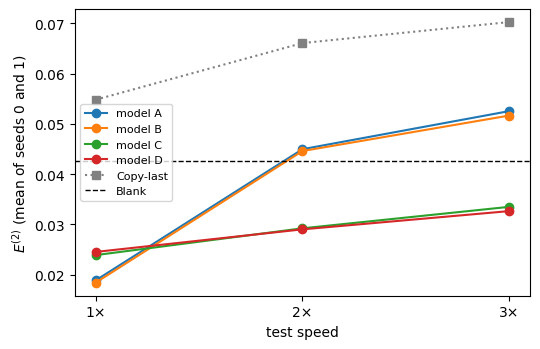

In [ ]:
fig, ax = plt.subplots(figsize=(5.5, 3.6))
for name in MODEL_SPECS:
    ax.plot(SPEEDS, [mean2(name, f"E2_{k}x") for k in SPEEDS], marker="o", label=f"model {name}")
ax.plot(SPEEDS, [E_speed("Copy-last", k, 2) for k in SPEEDS], marker="s", color="gray", linestyle=":", label="Copy-last")
ax.axhline(E_H(mse_blank, mask_1x, 2), color="black", linestyle="--", linewidth=1, label="Blank")
ax.set_xticks(SPEEDS); ax.set_xticklabels([f"{k}×" for k in SPEEDS])
ax.set_xlabel("test speed"); ax.set_ylabel("$E^{(2)}$ (mean of seeds 0 and 1)")
ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(f"{OUT}/E2_vs_speed_ABCD.png", dpi=200); plt.show()

## The final model

In [ ]:
class Symmetrised(nn.Module):
    def __init__(self, f):
        super().__init__()
        self.f = f

    def forward(self, X):
        B = X.shape[0]
        Y_g = self.f(torch.cat([apply_g(g, X) for g in G], dim=0))
        return torch.stack([apply_g_inverse(g, Y_g[i * B:(i + 1) * B]) for i, g in enumerate(G)]).mean(dim=0)

with torch.no_grad():
    X_chk = make_window(to_float(test_u8[:64]).to(device), t=1, k=1)[0]
    for name in ["B", "D"]:
        fb = Symmetrised(models[(name, 0)]).eval()
        for n, T in TRANSFORMS.items():
            print(f"symmetrised {name}, T = {n}: max |f_bar(T(X)) - T(f_bar(X))| = "
                  f"{(fb(T(X_chk)) - T(fb(X_chk))).abs().max().item():.2e}")

symmetrised B, T = M: max |f_bar(T(X)) - T(f_bar(X))| = 1.19e-07
symmetrised B, T = R: max |f_bar(T(X)) - T(f_bar(X))| = 1.19e-07
symmetrised D, T = M: max |f_bar(T(X)) - T(f_bar(X))| = 5.96e-08
symmetrised D, T = R: max |f_bar(T(X)) - T(f_bar(X))| = 5.96e-08


### Training D+B

In [ ]:
MODEL_SPECS["D+B"] = (ModelD, "speed", True)
for s in SEEDS:
    models[("D+B", s)], hists[("D+B", s)] = train_model(ModelD, "model_DB", s, regime="speed", symmetry_aug=True)

model_DB seed 0 | epoch  1/30 | train loss 4.647e-02 | val E5 3.947e-02 | 17.8 s
model_DB seed 0 | epoch  2/30 | train loss 4.021e-02 | val E5 3.947e-02 | 18.3 s
model_DB seed 0 | epoch  3/30 | train loss 4.005e-02 | val E5 3.906e-02 | 18.0 s
model_DB seed 0 | epoch  4/30 | train loss 3.948e-02 | val E5 3.846e-02 | 17.5 s
model_DB seed 0 | epoch  5/30 | train loss 3.859e-02 | val E5 3.697e-02 | 17.5 s
model_DB seed 0 | epoch  6/30 | train loss 3.749e-02 | val E5 3.598e-02 | 17.6 s
model_DB seed 0 | epoch  7/30 | train loss 3.643e-02 | val E5 3.461e-02 | 17.8 s
model_DB seed 0 | epoch  8/30 | train loss 3.557e-02 | val E5 3.461e-02 | 18.0 s
model_DB seed 0 | epoch  9/30 | train loss 3.492e-02 | val E5 3.301e-02 | 17.8 s
model_DB seed 0 | epoch 10/30 | train loss 3.424e-02 | val E5 3.231e-02 | 17.8 s
model_DB seed 0 | epoch 11/30 | train loss 3.371e-02 | val E5 3.165e-02 | 17.8 s
model_DB seed 0 | epoch 12/30 | train loss 3.334e-02 | val E5 3.094e-02 | 17.8 s
model_DB seed 0 | epoch 13/3

### Table 6

In [ ]:
def evaluate(predict, hist):
    predict.eval()
    r = {}
    for k in SPEEDS:
        mse, mask = per_horizon_mse(predict, test_u8, t=1, k=k)
        r[f"E2_{k}x"] = E_H(mse, mask, 2)
        if k == 1:
            r["E5_1x"] = E_H(mse, mask, 5)
    for n, T in TRANSFORMS.items():
        C, E = consistency_metrics(predict, test_u8, T)
        r[f"C_{n}"], r[f"E_{n}"] = C.mean().item(), E.mean().item()
    r["params"] = count_parameters(predict)
    r["train_s"] = float(np.mean(hist["epoch_time_s"]))
    r["infer_s"] = inference_time(predict, test_u8)
    return r

for s in SEEDS:
    results[("D+B", s)] = evaluate(models[("D+B", s)], hists[("D+B", s)])
sym_results = {(name, s): evaluate(Symmetrised(models[(name, s)]), hists[(name, s)])
               for name in ["B", "D", "D+B"] for s in SEEDS}
with open(f"{OUT}/table6_raw.json", "w") as fh:
    json.dump({"hardware": HARDWARE,
               **{f"sym_{n}_seed{s}": r for (n, s), r in sym_results.items()},
               **{f"{n}_seed{s}": results[(n, s)] for n in ["D+B"] for s in SEEDS}}, fh, indent=2)

def fmt_sci_seeds(v0, v1):
    return f"{(v0 + v1) / 2:.2e} ({v0:.2e}, {v1:.2e})"

def table_rows(res, names, label):
    rows = []
    for name in names:
        r0, r1 = res[(name, 0)], res[(name, 1)]
        cells = [fmt_sci_seeds(r0[key], r1[key]) if key in ("C_M", "C_R") else fmt_seeds(r0[key], r1[key])
                 for _, key in cols]
        rows.append(f"| {label(name)} | " + " | ".join(cells) + f" | {r0['params']:,} |")
    return rows

header = ["| Model | " + " | ".join(c[0] for c in cols) + " | Trainable parameters |", "|---|" + "---|" * (len(cols) + 1)]
lines = [f"**Table 6: symmetrised forecasters on the test set (t = 1); entries are mean (seed 0, seed 1); "
         f"training time is that of the underlying learned model; hardware: {HARDWARE}. "
         f"The final model is symmetrised D+B.**", ""] + header
lines += table_rows(sym_results, ["B", "D", "D+B"], lambda n: f"symmetrised {n}" + (" (final)" if n == "D+B" else ""))
table6 = "\n".join(lines)
display(Markdown(table6))
with open(f"{OUT}/table6.md", "w") as fh:
    fh.write(table6 + "\n")

lines = ["**Supplementary: unsymmetrised D+B (Table 5 columns).**", ""] + header
lines += table_rows(results, ["D+B"], lambda n: n)
display(Markdown("\n".join(lines)))

keys = [("E⁽⁵⁾ 1×", "E5_1x"), ("E_M", "E_M"), ("E_R", "E_R"), ("E⁽²⁾ 3×", "E2_3x"), ("Inference time (s)", "infer_s")]
lines = ["**Effect of symmetrisation (seed means).**", "",
         "| Model | " + " | ".join(f"{k} learned | {k} symmetrised" for k, _ in keys) + " |", "|---|" + "---|" * (2 * len(keys))]
for name in ["B", "D", "D+B"]:
    cells = []
    for _, key in keys:
        a = (results[(name, 0)][key] + results[(name, 1)][key]) / 2
        b = (sym_results[(name, 0)][key] + sym_results[(name, 1)][key]) / 2
        cells += [fmt(a), fmt(b)]
    lines.append(f"| {name} | " + " | ".join(cells) + " |")
display(Markdown("\n".join(lines)))

**Table 6: symmetrised forecasters on the test set (t = 1); entries are mean (seed 0, seed 1); training time is that of the underlying learned model; hardware: Tesla T4. The final model is symmetrised D+B.**

| Model | E⁽⁵⁾ 1× | C_M | E_M | C_R | E_R | E⁽²⁾ 1× | E⁽²⁾ 2× | E⁽²⁾ 3× | Train time / epoch (s) | Inference time (s) | Trainable parameters |
|---|---|---|---|---|---|---|---|---|---|---|---|
| symmetrised B | 0.0215 (0.0223, 0.0207) | 4.63e-17 (4.34e-17, 4.92e-17) | 0.0215 (0.0223, 0.0207) | 4.74e-17 (4.43e-17, 5.04e-17) | 0.0215 (0.0223, 0.0207) | 0.0179 (0.0184, 0.0174) | 0.0437 (0.0439, 0.0436) | 0.0504 (0.0509, 0.0499) | 12.4 (12.4, 12.4) | 7.64 (7.64, 7.64) | 480,784 |
| symmetrised D | 0.0274 (0.0275, 0.0274) | 3.57e-17 (3.40e-17, 3.74e-17) | 0.0274 (0.0275, 0.0274) | 3.68e-17 (3.51e-17, 3.85e-17) | 0.0274 (0.0275, 0.0274) | 0.0244 (0.0246, 0.0242) | 0.0290 (0.0291, 0.0289) | 0.0325 (0.0325, 0.0325) | 17.3 (17.3, 17.3) | 7.00 (7.00, 7.00) | 480,784 |
| symmetrised D+B (final) | 0.0279 (0.0276, 0.0282) | 3.10e-17 (2.98e-17, 3.22e-17) | 0.0279 (0.0276, 0.0282) | 3.16e-17 (3.04e-17, 3.29e-17) | 0.0279 (0.0276, 0.0282) | 0.0247 (0.0248, 0.0246) | 0.0294 (0.0294, 0.0295) | 0.0328 (0.0325, 0.0330) | 17.8 (17.8, 17.8) | 7.00 (6.99, 7.02) | 480,784 |

**Supplementary: unsymmetrised D+B (Table 5 columns).**

| Model | E⁽⁵⁾ 1× | C_M | E_M | C_R | E_R | E⁽²⁾ 1× | E⁽²⁾ 2× | E⁽²⁾ 3× | Train time / epoch (s) | Inference time (s) | Trainable parameters |
|---|---|---|---|---|---|---|---|---|---|---|---|
| D+B | 0.0281 (0.0278, 0.0283) | 2.50e-04 (2.96e-04, 2.05e-04) | 0.0281 (0.0278, 0.0283) | 2.89e-04 (3.80e-04, 1.99e-04) | 0.0280 (0.0278, 0.0283) | 0.0248 (0.0249, 0.0247) | 0.0296 (0.0295, 0.0296) | 0.0329 (0.0327, 0.0331) | 17.8 (17.8, 17.8) | 0.644 (0.645, 0.644) | 480,784 |

**Effect of symmetrisation (seed means).**

| Model | E⁽⁵⁾ 1× learned | E⁽⁵⁾ 1× symmetrised | E_M learned | E_M symmetrised | E_R learned | E_R symmetrised | E⁽²⁾ 3× learned | E⁽²⁾ 3× symmetrised | Inference time (s) learned | Inference time (s) symmetrised |
|---|---|---|---|---|---|---|---|---|---|---|
| B | 0.0222 | 0.0215 | 0.0222 | 0.0215 | 0.0222 | 0.0215 | 0.0516 | 0.0504 | 0.394 | 7.64 |
| D | 0.0275 | 0.0274 | 0.0277 | 0.0274 | 0.0286 | 0.0274 | 0.0326 | 0.0325 | 0.641 | 7.00 |
| D+B | 0.0281 | 0.0279 | 0.0281 | 0.0279 | 0.0280 | 0.0279 | 0.0329 | 0.0328 | 0.644 | 7.00 |

### Figure 6(a)

T = M: video 9256 | final model: per-video C_M = 4.28e-17, E_M = 0.0336 | model A (seed 0): per-video C_M = 0.00469
T = M: video 9269 | final model: per-video C_M = 5.40e-17, E_M = 0.0385 | model A (seed 0): per-video C_M = 0.00448
T = R: video 9733 | final model: per-video C_R = 4.64e-17, E_R = 0.0327 | model A (seed 0): per-video C_R = 0.00662
T = R: video 9254 | final model: per-video C_R = 3.91e-17, E_R = 0.036 | model A (seed 0): per-video C_R = 0.00647


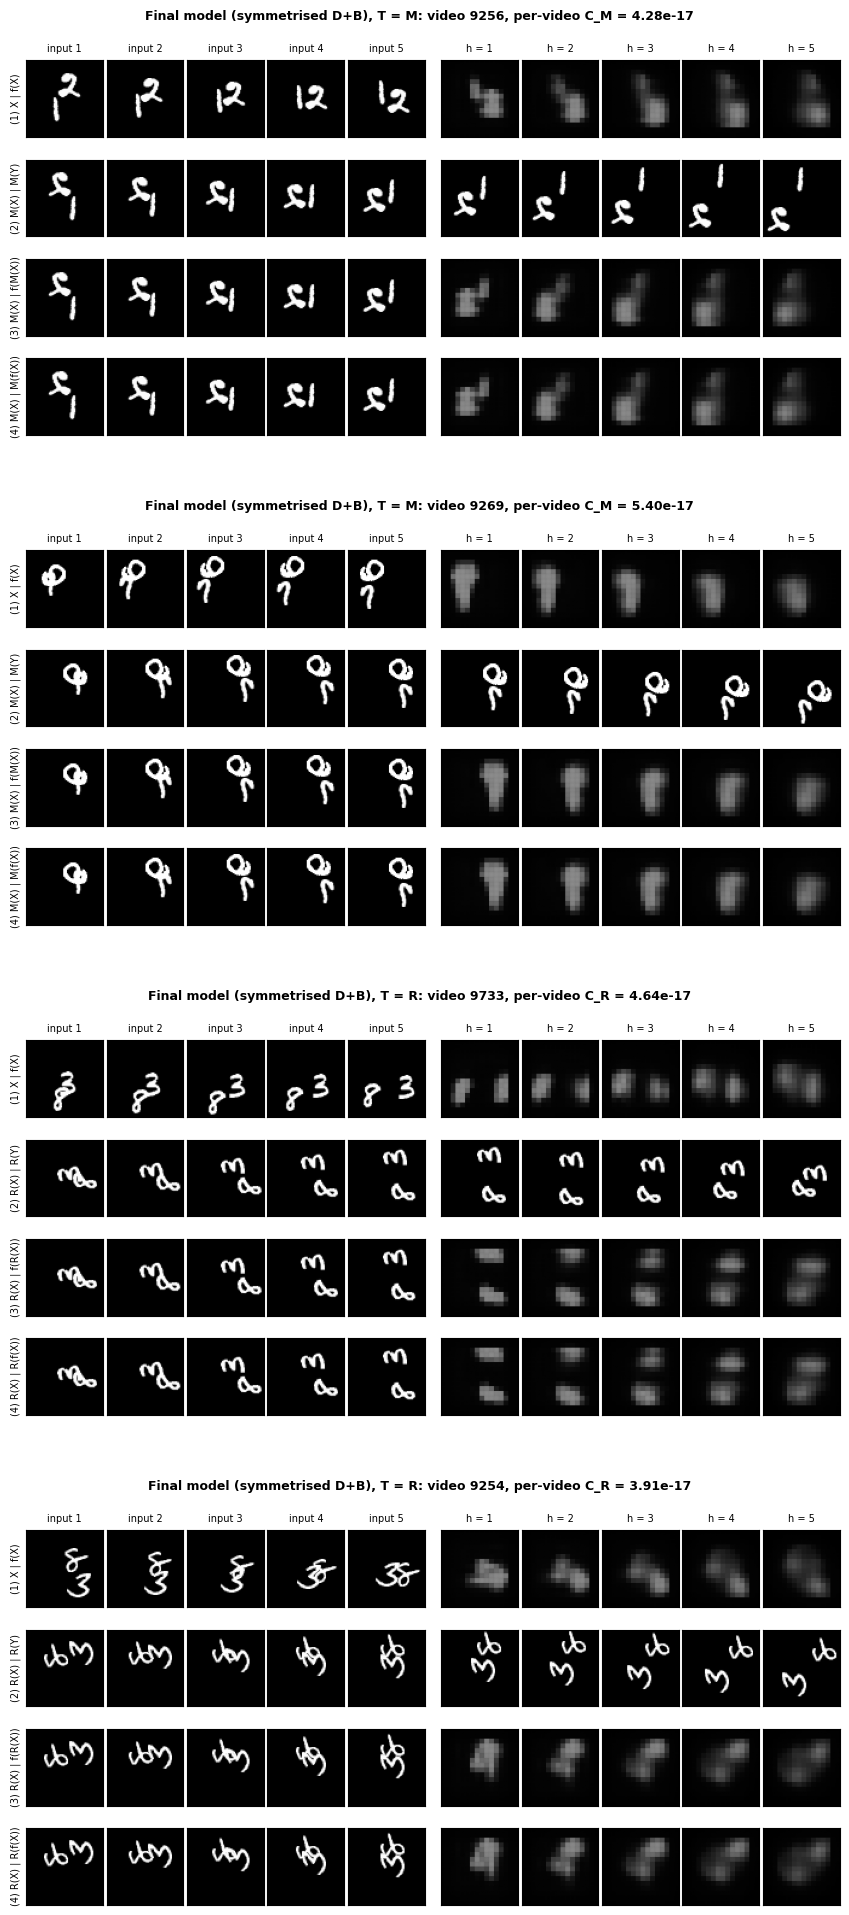

GIFs for Figure 6(a) (copy into your repository and cite in the caption):
   gifs/figure6a_M_video9256.gif
   gifs/figure6a_M_video9269.gif
   gifs/figure6a_R_video9733.gif
   gifs/figure6a_R_video9254.gif


In [ ]:
final = Symmetrised(models[("D+B", 0)]).eval()

@torch.no_grad()
def panel_rows_f(f, vi, n):
    T = TRANSFORMS[n]
    X, Y, _ = make_window(to_float(test_u8[vi:vi + 1]).to(device), t=1, k=1)
    f_X, f_TX = f(X), f(T(X))
    rows = [("(1) X | f(X)", X, f_X),
            (f"(2) {n}(X) | {n}(Y)", T(X), T(Y)),
            (f"(3) {n}(X) | f({n}(X))", T(X), f_TX),
            (f"(4) {n}(X) | {n}(f(X))", T(X), T(f_X))]
    return [(lab, a[0, :, 0].cpu().numpy(), b[0, :, 0].cpu().numpy()) for lab, a, b in rows]

fig6_C = {}
for n, vi in fig3_panels:
    C_v, E_v = consistency_metrics(final, test_u8[vi:vi + 1], TRANSFORMS[n])
    fig6_C[(n, vi)] = (C_v.item(), E_v.item())
    print(f"T = {n}: video {9000 + vi} | final model: per-video C_{n} = {C_v.item():.2e}, E_{n} = {E_v.item():.3g}"
          f" | model A (seed 0): per-video C_{n} = {C_seed0[n][vi].item():.3g}")

n_pan = len(fig3_panels)
fig = plt.figure(figsize=(10.5, 4.9 * n_pan))
for sf, (n, vi) in zip(np.atleast_1d(fig.subfigures(n_pan, 1)), fig3_panels):
    rows = panel_rows_f(final, vi, n)
    gs = sf.add_gridspec(4, 11, width_ratios=[1] * 5 + [0.12] + [1] * 5, hspace=0.25, wspace=0.05)
    for r, (lab, inp, fut) in enumerate(rows):
        for c in range(10):
            ax = sf.add_subplot(gs[r, c if c < 5 else c + 1])
            ax.imshow(inp[c] if c < 5 else fut[c - 5], cmap="gray", vmin=0, vmax=1)
            ax.set_xticks([]); ax.set_yticks([])
            if r == 0:
                ax.set_title(f"input {c + 1}" if c < 5 else f"h = {c - 4}", fontsize=7)
            if c == 0:
                ax.set_ylabel(lab, fontsize=7)
    sf.suptitle(f"Final model (symmetrised D+B), T = {n}: video {9000 + vi}, per-video C_{n} = {fig6_C[(n, vi)][0]:.2e}",
                fontsize=9, weight="bold")
fig.savefig(f"{OUT}/figure6a_final.png", dpi=200, bbox_inches="tight")
plt.show()

gif6_paths = []
for n, vi in fig3_panels:
    rows = panel_rows_f(final, vi, n)
    frames = []
    for h in range(5):
        f, ax = plt.subplots(4, 2, figsize=(3.6, 6.6))
        for r, (lab, inp, fut) in enumerate(rows):
            ax[r, 0].imshow(inp[-1], cmap="gray", vmin=0, vmax=1)
            ax[r, 1].imshow(fut[h], cmap="gray", vmin=0, vmax=1)
            ax[r, 0].set_ylabel(lab, fontsize=7)
            for a in ax[r]:
                a.set_xticks([]); a.set_yticks([])
        ax[0, 0].set_title("input 5", fontsize=8)
        ax[0, 1].set_title(f"h = {h + 1}", fontsize=8)
        f.suptitle(f"Final model, T = {n}, video {9000 + vi}", fontsize=9)
        f.tight_layout()
        f.canvas.draw()
        frames.append(Image.fromarray(np.asarray(f.canvas.buffer_rgba())[..., :3].copy()))
        plt.close(f)
    path = f"{GIF_DIR}/figure6a_{n}_video{9000 + vi}.gif"
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=700, loop=0)
    gif6_paths.append(path)
print("GIFs for Figure 6(a) (copy into your repository and cite in the caption):")
for p in gif6_paths:
    print("  ", p.replace(OUT + "/", ""))

### Figure 6(b)

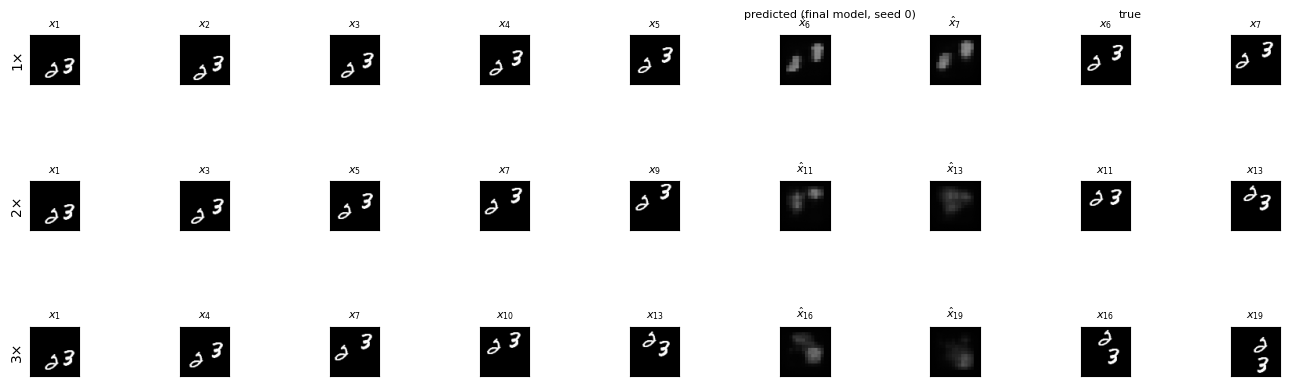

Figure 6(b) video: test video 26 (dataset index 9026), same as Figure 5


In [ ]:
fig, axes = plt.subplots(3, 9, figsize=(13, 4.8))
for r, k in enumerate(SPEEDS):
    X, Y, mask = make_window(to_float(test_u8[FIG5_VIDEO:FIG5_VIDEO + 1]).to(device), t=1, k=k)
    with torch.no_grad():
        Y_hat = final(X)
    ins, tgs = window_frames(1, k)
    panels = ([(X[0, j, 0], f"$x_{{{ins[j]}}}$") for j in range(5)]
              + [(Y_hat[0, j, 0], f"$\\hat{{x}}_{{{tgs[j]}}}$") for j in range(2)]
              + [(Y[0, j, 0], f"$x_{{{tgs[j]}}}$") for j in range(2)])
    for c, (img, title) in enumerate(panels):
        ax = axes[r, c]
        ax.imshow(img.cpu(), cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(title, fontsize=8)
    axes[r, 0].set_ylabel(f"{k}×", fontsize=10)
axes[0, 5].annotate("predicted (final model, seed 0)", (1.0, 1.35), xycoords="axes fraction", ha="center", fontsize=8)
axes[0, 7].annotate("true", (1.0, 1.35), xycoords="axes fraction", ha="center", fontsize=8)
fig.tight_layout()
fig.savefig(f"{OUT}/figure6b_final.png", dpi=200)
plt.show()
print(f"Figure 6(b) video: test video {FIG5_VIDEO} (dataset index {9000 + FIG5_VIDEO}), same as Figure 5")